In [2]:
!pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -------- ------------------------------- 2.4/11.3 MB 18.1 MB/s eta 0:00:01
   ------------------------------------- -- 10.7/11.3 MB 32.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 21.6 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- -


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Original Dataset:
   Area  Rooms  Age  Location_Score     Price
0   778      1    6               3   5081030
1  2148      4   27               8  11863210
2  1909      3    3               5  11371453
3  1478      3   16               3   9079771
4  1466      3   14               4   7502204

Missing Values:
Area              0
Rooms             0
Age               0
Location_Score    0
Price             0
dtype: int64

Duplicate Values: 0

Cleaned Dataset:
     Area  Rooms  Age  Location_Score     Price
0     778      1    6               3   5081030
1    2148      4   27               8  11863210
2    1909      3    3               5  11371453
3    1478      3   16               3   9079771
4    1466      3   14               4   7502204
..    ...    ...  ...             ...       ...
115  1738      3    0               8  11524125
116   674      1   20               7   4521173
117   879      2    3               7   6833906
118  1091      3    8               7   8325484
119   829

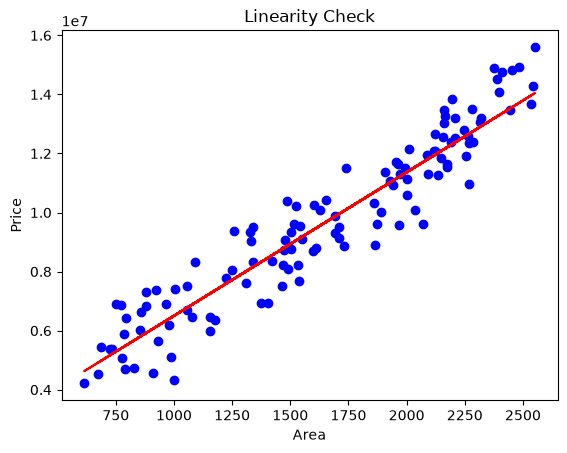

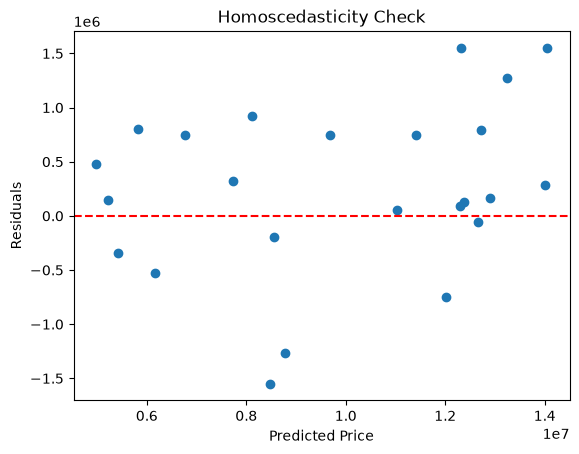

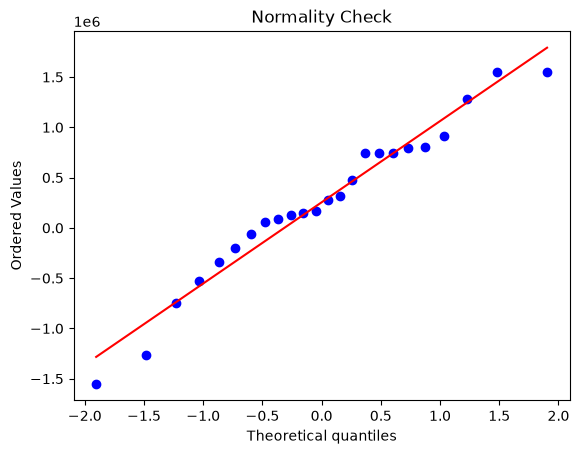

Durbin Watson: 2.0246356160048573

Predicted House Price: 10392202.012154788


In [5]:

# SIMPLE LINEAR REGRESSION

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.stattools import durbin_watson

# 2. Import CSV file
df = pd.read_csv("housing_clean.csv")

print("Original Dataset:")
print(df.head())

# 3. Data Cleaning
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))

print("\nCleaned Dataset:")
print(df)

# 4. Select variables
X = df[['Area']]
y = df['Price']

# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Build and train model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nIntercept:", model.intercept_)
print("Coefficient:", model.coef_)

# 7. Evaluate model
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nR2 Score:", r2)
print("RMSE:", rmse)

# 8. Check assumptions

# Linearity
plt.scatter(df['Area'], df['Price'], color='blue')
plt.plot(df['Area'], model.predict(df[['Area']]), color='red')
plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Linearity Check")
plt.show()

# Homoscedasticity
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Check")
plt.show()

# Normality
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normality Check")
plt.show()

# Independence
print("Durbin Watson:", durbin_watson(residuals))

# 9. Predict new house price
new_house = pd.DataFrame({'Area': [1800]})

prediction = model.predict(new_house)

print("\nPredicted House Price:", prediction[0])


Original Dataset:
   Area  Rooms  Age  Location_Score     Price
0   778      1    6               3   5081030
1  2148      4   27               8  11863210
2  1909      3    3               5  11371453
3  1478      3   16               3   9079771
4  1466      3   14               4   7502204

Missing Values:
Area              0
Rooms             0
Age               0
Location_Score    0
Price             0
dtype: int64

Duplicate Values: 0

Cleaned Dataset:
     Area  Rooms  Age  Location_Score     Price
0     778      1    6               3   5081030
1    2148      4   27               8  11863210
2    1909      3    3               5  11371453
3    1478      3   16               3   9079771
4    1466      3   14               4   7502204
..    ...    ...  ...             ...       ...
115  1738      3    0               8  11524125
116   674      1   20               7   4521173
117   879      2    3               7   6833906
118  1091      3    8               7   8325484
119   829

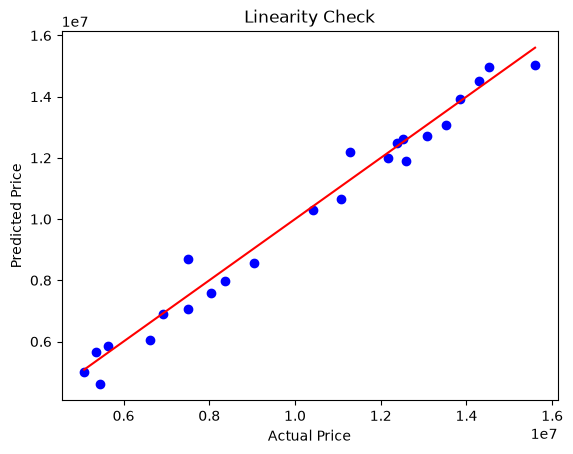

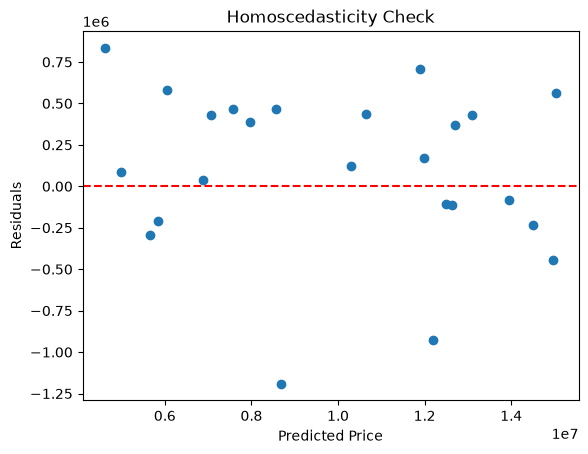

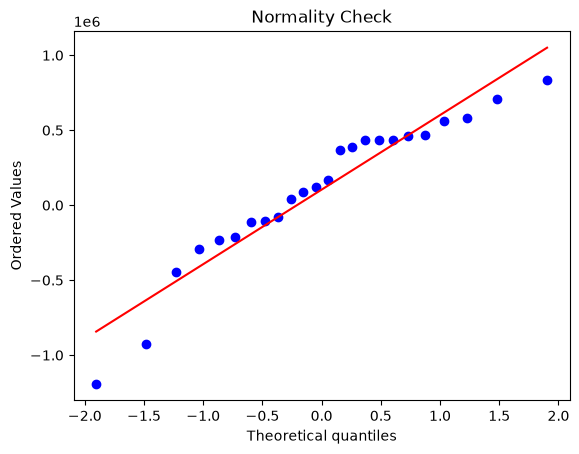

Durbin Watson: 1.7708519769150382

Predicted House Price: 10835640.646165434


In [8]:

# MULTIPLE LINEAR REGRESSION

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.stattools import durbin_watson

# 2. Import CSV file
df = pd.read_csv("housing_clean.csv")

print("Original Dataset:")
print(df.head())

# 3. Data Cleaning
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))

print("\nCleaned Dataset:")
print(df)

# 4. Select variables
X = df[['Area', 'Rooms', 'Age', 'Location_Score']]
y = df['Price']

# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Build and train model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nIntercept:", model.intercept_)
print("Coefficients:", model.coef_)

# 7. Evaluate model
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nR2 Score:", r2)
print("RMSE:", rmse)

# 8. Check assumptions

# Linearity
plt.scatter(y_test, y_pred, color='blue')
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linearity Check")
plt.show()

# Homoscedasticity
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Homoscedasticity Check")
plt.show()

# Normality
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normality Check")
plt.show()

# Independence
print("Durbin Watson:", durbin_watson(residuals))

# 9. Predict new house price
new_house = pd.DataFrame({
    'Area': [1800],
    'Rooms': [3],
    'Age': [10],
    'Location_Score': [7]
})

prediction = model.predict(new_house)

print("\nPredicted House Price:", prediction[0])
